# Assignment 05: Raster Data and Environmental Covariates

## BIO597 Spatial Analysis of Biodiversity

This assignment asks you to repeat and extend the raster workflow from Lab 05. You will clip WorldClim rasters to Maine, extract environmental values for selected amphibian occurrences, compare species, and document your predictor choices.

## Deliverable

Submit a completed notebook containing code, raster maps, an occurrence-environment table, and species summaries.

## Learning goals

By the end of this assignment, you should be able to:

* inspect raster metadata and identify alignment problems
* clip global rasters to a study-area polygon
* extract raster values at point locations
* recognize and retain NoData values
* select predictors based on ecological meaning rather than availability alone
* document a reproducible environmental-data workflow

## Data

Use:

* `Amphibians_ME/Amphibians_ME.csv` for occurrence records
* `/home/jovyan/shared-readwrite/bioclim` for WorldClim 2.1 bioclimatic rasters
* `../labs/ME_ShapeFiles/Maine_State_Boundary.shp` for the clipping boundary

The WorldClim files represent 1970–2000 climate normals at 2.5 arc-minute resolution. Variable definitions are available from the [WorldClim bioclimatic variable page](https://www.worldclim.org/data/bioclim.html).

## 1. Import packages

Import `pandas`, `geopandas`, `rioxarray`, and `xarray` using the same abbreviations as Lab 05.
Also import `Path` from the `pathlib` module as we did previously

In [2]:
import pandas as pd
import geopandas as gpd
import rioxarray as rxr
import xarray as xr
from pathlib import Path

## 2. Load and combine the Maine boundary

Read `Maine_State_Boundary.shp`. Inspect its CRS and shape, then use `dissolve()` to combine the polygons.

In [12]:
boundary_path = Path("../labs/ME_ShapeFiles")
maine_boundary = gpd.read_file(boundary_path /"Maine_State_Boundary.shp")
print(maine_boundary.shape)
print(maine_boundary.crs)
maine_boundary = maine_boundary.dissolve()
print(maine_boundary)

(6204, 10)
EPSG:4326
                                            geometry  OBJECTID LAND  \
0  MULTIPOLYGON (((-70.60685 42.97751, -70.60673 ...         1    y   

                               GlobalID                    created_us  \
0  25ab82ef-ffa7-4098-a01a-01a5c1dfc6fc  Emily.Pettit@maine.gov_maine   

  created_da                    last_edite last_edi_1    Shape__Are  \
0 2021-08-02  Emily.Pettit@maine.gov_maine 2021-08-02  8.302555e+10   

     Shape__Len  
0  5.736060e+06  


## 3. Open annual mean temperature

Open `wc2.1_2.5m_bio_1.tif` with `masked=True`. Store the result as `bio1`.

In [13]:
bioclim_path = Path("/home/jovyan/shared/bioclim")
bio1_path = bioclim_path / "wc2.1_2.5m_bio_1.tif"

bio1 = rxr.open_rasterio(
    bioclim_path / "wc2.1_2.5m_bio_1.tif",
    masked= True,
)

bio1

<xarray.DataArray (band: 1, y: 4320, x: 8640)> Size: 149MB
[37324800 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 35kB 89.98 89.94 89.9 89.85 ... -89.9 -89.94 -89.98
  * x            (x) float64 69kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  31.166666030884
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  -54.759166717529
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

## 4. Inspect annual mean temperature metadata

Report:

* dimensions and shape
* data type
* CRS
* resolution
* bounds
* NoData value

Add a brief comment beside each output explaining what it describes.

In [44]:
print("Dimensions:", bio1.dims) ## Names the dimenions of the raster
print("Shape:", bio1.shape) ## The number of bands, rows, and columns
print("Data type:", bio1.dtype) ## Type of data in each cell, in this case: 32-bit floating point numbers
print("CRS:", bio1.rio.crs) ## How coordinates locate the raster on Earth
print("Resolution:", bio1.rio.resolution()) ## Cell width and heigh in coordinate units
print("Bounds:", bio1.rio.bounds()) ## Extent of the data (latitude/longitude), in this case: the whole globe
print("NoData:", bio1.rio.nodata) ## Used to flag cells that do not contain a valid measurement

Dimensions: ('band', 'y', 'x')
Shape: (1, 4320, 8640)
Data type: float32
CRS: EPSG:4326
Resolution: (0.041666666666666664, -0.041666666666666664)
Bounds: (-180.0, -89.99999999999997, 180.0, 90.0)
NoData: nan


## 5. Clip BIO1 to Maine

Use `rio.clip()` with the dissolved boundary. Set `drop=True` and `from_disk=True`, then remove the one-band dimension with `squeeze()`.

In [15]:
bio1_maine = bio1.rio.clip(
    maine_boundary.geometry,
    maine_boundary.crs,
    drop= True,
    from_disk= True,
)

bio1_maine = bio1_maine.squeeze()
bio1_maine

<xarray.DataArray (y: 109, x: 101)> Size: 88kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(109, 101))
Coordinates:
  * y            (y) float64 872B 47.48 47.44 47.4 47.35 ... 43.06 43.02 42.98
  * x            (x) float64 808B -71.1 -71.06 -71.02 ... -67.02 -66.98 -66.94
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  31.166666030884
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  -54.759166717529
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

## 6. Compare the global and clipped rasters

Display the shape, bounds, CRS, and resolution of both. State which properties changed and which remained the same.

In [16]:
print("Global shape:", bio1.shape) ## Same: 1 band, 4320 rows, 8640 columns
print("Maine shape:", bio1_maine.shape) ## Changed: 109 rows, 101 columns
print("Bounds:", bio1.rio.bounds())
print("Maine bounds:", bio1_maine.rio.bounds()) ## Changed: latitude/longitude bounds restricted to Maine boundary
print("CRS:", bio1.rio.crs)
print("Maine CRS:", bio1_maine.rio.crs)
print("Resolution:", bio1.rio.resolution())
print("Maine resolution:", bio1_maine.rio.resolution()) ## Same: resolution is maintained

Global shape: (1, 4320, 8640)
Maine shape: (109, 101)
Bounds: (-180.0, -89.99999999999997, 180.0, 90.0)
Maine bounds: (-71.125, 42.95833333333333, -66.91666666666667, 47.5)
CRS: EPSG:4326
Maine CRS: EPSG:4326
Resolution: (0.041666666666666664, -0.041666666666666664)
Maine resolution: (0.04166666666666671, -0.041666666666666664)


**Your comparison:**
- The *shape* changed: Maine shape has 109 rows and 101 columns
- The *bounds* changed: Global -> Maine state boundary
- The *CRS* and *resolution* is maintained

## 7. Plot annual mean temperature for Maine

Use the DataArray's `.plot()` method and choose an appropriate colormap.

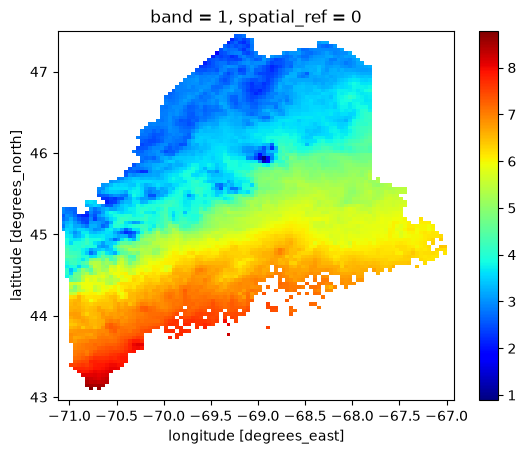

In [17]:
bio1_maine.plot(cmap="jet")

## 8. Choose three additional bioclimatic variables

Choose three variables from BIO2 through BIO19. Include at least one temperature variable and at least one precipitation variable.

Do not choose variables only because they are available. Give a short biological reason for each choice.

**Variable 1 and justification:**
    Variable 1: BIO6 - Minimum temperature during the coldest month.
    Justification: Since amphibians are ectotherms, I expect that extremely cold temperatures to cause stress.

**Variable 2 and justification:**
    Variable 2: BIO9 - Mean temperature of driest quarter.
    Justification: I expect temperature and precipitation to have additive stress on amphibians (i.e. low temp/low precip).

**Variable 3 and justification:**
    Variable 3: BIO14 - Precipitation of driest month.
    Justification: I expect dry conditions to cause stress on amphibians.

## 9. Open the first additional raster

Build its filename, open it with `masked=True`, and inspect its CRS, shape, resolution, and bounds.

In [18]:
bio6 = rxr.open_rasterio(
    bioclim_path / "wc2.1_2.5m_bio_6.tif",
    masked=True,
)

print("CRS:", bio6.rio.crs)
print("Shape", bio6.shape)
print("Resolution:", bio6.rio.resolution())
print("Bounds:", bio6.rio.bounds())

CRS: EPSG:4326
Shape (1, 4320, 8640)
Resolution: (0.041666666666666664, -0.041666666666666664)
Bounds: (-180.0, -89.99999999999997, 180.0, 90.0)


## 10. Check alignment with BIO1

Compare CRS, shape, resolution, and bounds. Each comparison should return `True` before you treat the rasters as an aligned stack.

In [19]:
print("Same CRS:", bio1.rio.crs == bio6.rio.crs)
print("Same shape:", bio1.shape == bio6.shape)
print("Same resolution:", bio1.rio.resolution() == bio6.rio.resolution())
print("Same bounds:", bio1.rio.bounds() == bio6.rio.bounds())

Same CRS: True
Same shape: True
Same resolution: True
Same bounds: True


## 11. Clip and map the first additional raster

Use the same clipping settings as BIO1. Plot the Maine result with an appropriate colormap.

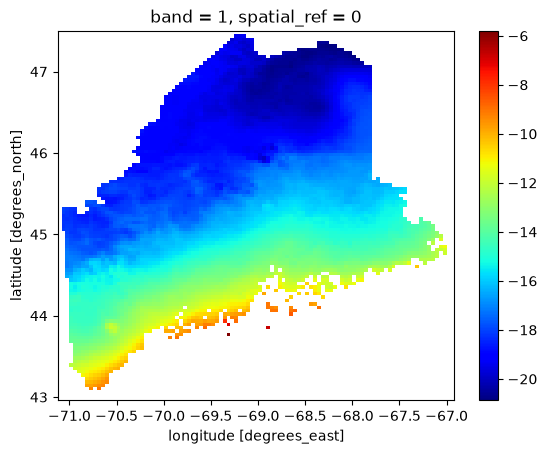

In [20]:
## BIO6 - Min Temp of Coldest Month
# Clip, squeeze, and plot the first additional raster.
bio6_maine = bio6.rio.clip(
    maine_boundary.geometry,
    maine_boundary.crs,
    drop=True,
    from_disk=True,
)

bio6_maine = bio6_maine.squeeze()
bio6_maine.plot(cmap="jet")

## 12. Repeat for the second additional raster

Open the raster, confirm alignment, clip it to Maine, and plot it. Keep each part of the workflow visible in your code.

In [21]:
## BIO9 - Mean Temp of Driest Quarter
## Open BIO9
bio9 = rxr.open_rasterio(
    bioclim_path / "wc2.1_2.5m_bio_9.tif",
    masked=True,
)

print("CRS:", bio9.rio.crs)
print("Shape", bio9.shape)
print("Resolution:", bio9.rio.resolution())
print("Bounds:", bio9.rio.bounds())

CRS: EPSG:4326
Shape (1, 4320, 8640)
Resolution: (0.041666666666666664, -0.041666666666666664)
Bounds: (-180.0, -89.99999999999997, 180.0, 90.0)


In [22]:
## Confirm alignment
print("Same CRS:", bio1.rio.crs == bio9.rio.crs)
print("Same shape:", bio1.shape == bio9.shape)
print("Same resolution:", bio1.rio.resolution() == bio9.rio.resolution())
print("Same bounds:", bio1.rio.bounds() == bio9.rio.bounds())

Same CRS: True
Same shape: True
Same resolution: True
Same bounds: True


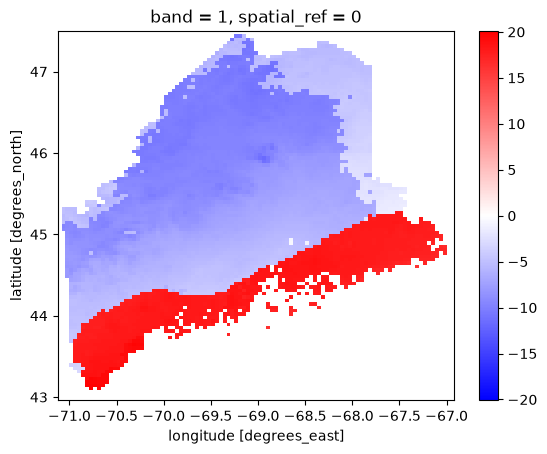

In [23]:
## Clip BIO9 to Maine boundary and plot
bio9_maine = bio9.rio.clip(
    maine_boundary.geometry,
    maine_boundary.crs,
    drop=True,
    from_disk=True,
)

bio9_maine = bio9_maine.squeeze()
bio9_maine.plot(cmap="bwr")

## 13. Repeat for the third additional raster

Open the raster, confirm alignment, clip it to Maine, and plot it.

In [24]:
## BIO14 - Precipitation of Driest Month
## Open BIO14
bio14 = rxr.open_rasterio(
    bioclim_path / "wc2.1_2.5m_bio_14.tif",
    masked=True,
)

print("CRS:", bio14.rio.crs)
print("Shape", bio14.shape)
print("Resolution:", bio14.rio.resolution())
print("Bounds:", bio14.rio.bounds())

CRS: EPSG:4326
Shape (1, 4320, 8640)
Resolution: (0.041666666666666664, -0.041666666666666664)
Bounds: (-180.0, -89.99999999999997, 180.0, 90.0)


In [25]:
## Confirm alignment
print("Same CRS:", bio1.rio.crs == bio14.rio.crs)
print("Same shape:", bio1.shape == bio14.shape)
print("Same resolution:", bio1.rio.resolution() == bio14.rio.resolution())
print("Same bounds:", bio1.rio.bounds() == bio14.rio.bounds())

Same CRS: True
Same shape: True
Same resolution: True
Same bounds: True


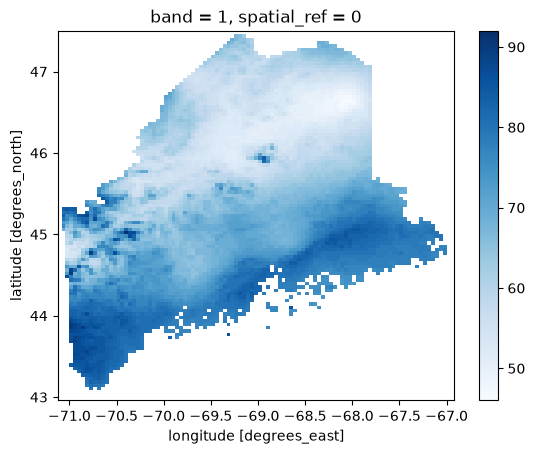

In [26]:
## Clip BIO14 to Maine boundary and plot
bio14_maine = bio14.rio.clip(
    maine_boundary.geometry,
    maine_boundary.crs,
    drop=True,
    from_disk=True,
)

bio14_maine = bio14_maine.squeeze()
bio14_maine.plot(cmap="Blues")

## 14. Load the amphibian records

Read the tab-delimited occurrence file. Keep `gbifID`, `species`, longitude, latitude, and year.

In [3]:
amphibians = pd.read_csv(
    "../assignments/Amphibians_ME/Amphibians_ME.csv",
    sep="\t",
    low_memory=False,
)

amphibians.shape

(25972, 50)

In [4]:
columns_to_keep = [
    "gbifID",
    "species",
    "decimalLongitude",
    "decimalLatitude",
    "year",
]

amphibians = amphibians[columns_to_keep]
amphibians.head()

,gbifID,species,decimalLongitude,decimalLatitude,year
0,6520738729,Lithobates catesbeianus,-68.660278,44.902551,2026.0
1,6520735611,Aquarana clamitans,-69.649014,44.735713,2026.0
2,6520729466,Boreorana sylvatica,-69.889241,44.798325,2026.0
3,6520721493,Lithobates palustris,-68.636788,44.860466,2022.0
4,6520718655,Lithobates pipiens,-68.788851,44.990948,2026.0


## 15. Prepare the occurrence coordinates

Convert longitude and latitude to numeric columns. Remove records missing species or coordinates.

In [5]:
# Convert both coordinate columns with pd.to_numeric().
amphibians["decimalLongitude"] = pd.to_numeric(
    amphibians["decimalLongitude"], errors="coerce"
)
amphibians["decimalLatitude"] = pd.to_numeric(
    amphibians["decimalLatitude"], errors="coerce"
)
# Drop rows missing species, longitude, or latitude.\
amphibians = amphibians.dropna(
    subset=["species", "decimalLongitude", "decimalLatitude"]
).copy()

amphibians.shape

(25586, 5)

## 16. Choose three amphibian species

Inspect the species counts, then choose three species with enough records for comparison.

In [6]:
amphibians["species"].value_counts().head(20)

species
Aquarana clamitans            2966
Plethodon cinereus            2864
Pseudacris crucifer           2801
Anaxyrus americanus           2800
Boreorana sylvatica           2794
Ambystoma maculatum           2511
Lithobates catesbeianus       2302
Lithobates palustris          1626
Dryophytes versicolor         1411
Notophthalmus viridescens     1029
Lithobates pipiens             561
Eurycea bislineata             516
Hemidactylium scutatum         334
Ambystoma laterale             322
Desmognathus fuscus            215
Aquarana septentrionalis       198
Gyrinophilus porphyriticus     134
Aquarana catesbeiana            81
Rana arvalis                    54
Ambystoma jeffersonianum        37
Name: count, dtype: int64

**Species 1:** *Aquarana clamitans*

**Species 2:** *Plethodon cinereus*

**Species 3:** *Pseudacris crucifer*

In [7]:
selected_species = [
    "Aquarana clamitans",
    "Plethodon cinereus",
    "Pseudacris crucifer",
]

selected_amphibians = amphibians[
    amphibians["species"].isin(selected_species)
]

## 17. Create an occurrence GeoDataFrame

Use longitude and latitude to create point geometry. Assign `EPSG:4326`.

In [10]:
# Create selected_amphibians_gdf here.
selected_amphibians_gdf = gpd.GeoDataFrame(
    selected_amphibians,
    geometry=gpd.points_from_xy(
        selected_amphibians["decimalLongitude"],
        selected_amphibians["decimalLatitude"],
    ),
    crs="EPSG:4326",
)

selected_amphibians_gdf.head()

,gbifID,species,decimalLongitude,decimalLatitude,year,geometry
1,6520735611,Aquarana clamitans,-69.649014,44.735713,2026.0,POINT (-69.64901 44.73571)
6,6520702458,Pseudacris crucifer,-68.704049,44.788417,2026.0,POINT (-68.70405 44.78842)
15,6520620737,Pseudacris crucifer,-70.850360,44.272807,2026.0,POINT (-70.85036 44.27281)
16,6520617346,Plethodon cinereus,-70.456871,43.994310,2026.0,POINT (-70.45687 43.99431)
17,6520610648,Aquarana clamitans,-70.399019,43.934882,2026.0,POINT (-70.39902 43.93488)


## 18. Confirm coordinate systems

Print the occurrence CRS and raster CRS. Explain what must be true before extracting raster values.

In [27]:
print(selected_amphibians_gdf.crs)
print(bio1_maine.rio.crs)

EPSG:4326
EPSG:4326


**Your explanation:**
The CRS for occurrence and raster must match. We need to have the same resolution, extent (or overlap), cell origin and boundaries in order to align the data layers.

## 19. Prepare coordinates for extraction

Create `xarray.DataArray` objects called `point_x` and `point_y`. Use one dimension named `record`.

In [28]:
point_x = xr.DataArray(
    selected_amphibians_gdf.geometry.x.to_numpy(),
    dims="record",
)

point_y = xr.DataArray(
    selected_amphibians_gdf.geometry.y.to_numpy(),
    dims="record",
)

## 20. Extract annual mean temperature

Use `.sel()` with `x`, `y`, and `method="nearest"`. Add the extracted values to a clearly named column in the occurrence GeoDataFrame.

In [29]:
bio1_values = bio1_maine.sel(
    x=point_x,
    y=point_y,
    method="nearest",
)

selected_amphibians_gdf["bio1_mean_temp_c"] = bio1_values 
selected_amphibians_gdf.head()

,gbifID,species,decimalLongitude,decimalLatitude,year,geometry,bio1_mean_temp_c
1,6520735611,Aquarana clamitans,-69.649014,44.735713,2026.0,POINT (-69.64901 44.73571),6.332833
6,6520702458,Pseudacris crucifer,-68.704049,44.788417,2026.0,POINT (-68.70405 44.78842),6.634333
15,6520620737,Pseudacris crucifer,-70.850360,44.272807,2026.0,POINT (-70.85036 44.27281),6.033667
16,6520617346,Plethodon cinereus,-70.456871,43.994310,2026.0,POINT (-70.45687 43.99431),6.875500
17,6520610648,Aquarana clamitans,-70.399019,43.934882,2026.0,POINT (-70.39902 43.93488),6.888000


## 21. Inspect missing extracted values

Count missing BIO1 values. Explain why coastal occurrences may be assigned NoData even when the coordinates are valid.

In [30]:
selected_amphibians_gdf["bio1_mean_temp_c"].isna().value_counts()

bio1_mean_temp_c
False    7612
True     1019
Name: count, dtype: int64

**Your explanation:** The coastline detail may differ between the raster and boundary, or the nearest cell center is over the ocean, or the coordinate uncertainty places the point near a cell edge.

## 22. Extract the three additional variables

Use the same `point_x` and `point_y` arrays. Add one clearly named column for each variable. The column names should include units where practical.

In [31]:
bio6_values = bio6_maine.sel(x=point_x, y=point_y, method="nearest") 
selected_amphibians_gdf["bio6_coldest_month_min_temp_c"] = bio6_values

In [32]:
bio9_values = bio9_maine.sel(x=point_x, y=point_y, method="nearest") 
selected_amphibians_gdf["bio9_driest_qrt_mean_temp_c"] = bio9_values

In [33]:
bio14_values = bio14_maine.sel(x=point_x, y=point_y, method="nearest") 
selected_amphibians_gdf["bio14_driest_month_precip_mm"] = bio14_values

## 23. Create the occurrence-environment table

Remove the geometry column and display the first five rows. Confirm that the table contains species, coordinates, year, and four environmental variables.

In [34]:
occurrence_environment = selected_amphibians_gdf.drop(columns="geometry")
occurrence_environment.head()

,gbifID,species,decimalLongitude,decimalLatitude,year,bio1_mean_temp_c,bio6_coldest_month_min_temp_c,bio9_driest_qrt_mean_temp_c,bio14_driest_month_precip_mm
1,6520735611,Aquarana clamitans,-69.649014,44.735713,2026.0,6.332833,-14.944000,-5.721334,65.0
6,6520702458,Pseudacris crucifer,-68.704049,44.788417,2026.0,6.634333,-13.624001,-5.006000,73.0
15,6520620737,Pseudacris crucifer,-70.850360,44.272807,2026.0,6.033667,-14.884000,-5.662000,77.0
16,6520617346,Plethodon cinereus,-70.456871,43.994310,2026.0,6.875500,-13.396000,17.938667,84.0
17,6520610648,Aquarana clamitans,-70.399019,43.934882,2026.0,6.888000,-13.096000,17.879999,85.0


## 24. Summarize environmental values by species

For each selected species, calculate:

* number of records
* mean of each environmental variable
* standard deviation of each environmental variable

In [41]:
predictor_columns = [
    "bio1_mean_temp_c",
    "bio6_coldest_month_min_temp_c",
    "bio9_driest_qrt_mean_temp_c",
    "bio14_driest_month_precip_mm",
]

for species, samples in occurrence_environment.groupby("species"):
    print(species, len(samples), ", Mean:", "\n", samples[predictor_columns].mean())
    print(species, len(samples), ", Standard Deviation:", "\n", samples[predictor_columns].std())

Aquarana clamitans 2966 , Mean: 
 bio1_mean_temp_c                  6.381768
bio6_coldest_month_min_temp_c   -13.424079
bio9_driest_qrt_mean_temp_c       7.212197
bio14_driest_month_precip_mm     73.787945
dtype: float64
Aquarana clamitans 2966 , Standard Deviation: 
 bio1_mean_temp_c                  1.321338
bio6_coldest_month_min_temp_c     2.808149
bio9_driest_qrt_mean_temp_c      12.350453
bio14_driest_month_precip_mm      8.272383
dtype: float64
Plethodon cinereus 2864 , Mean: 
 bio1_mean_temp_c                  6.868341
bio6_coldest_month_min_temp_c   -12.233288
bio9_driest_qrt_mean_temp_c      10.936433
bio14_driest_month_precip_mm     75.472259
dtype: float64
Plethodon cinereus 2864 , Standard Deviation: 
 bio1_mean_temp_c                  1.040450
bio6_coldest_month_min_temp_c     2.488493
bio9_driest_qrt_mean_temp_c      11.098607
bio14_driest_month_precip_mm      6.584116
dtype: float64
Pseudacris crucifer 2801 , Mean: 
 bio1_mean_temp_c                  6.551031
bio6_colde

## 25. Check relationships among predictors

Create a correlation table for your four environmental variables. Identify any pair with a strong relationship.

In [42]:
occurrence_environment[predictor_columns].corr().round(2)

,bio1_mean_temp_c,bio6_coldest_month_min_temp_c,bio9_driest_qrt_mean_temp_c,bio14_driest_month_precip_mm
bio1_mean_temp_c,1.00,0.94,0.74,0.80
bio6_coldest_month_min_temp_c,0.94,1.00,0.82,0.77
bio9_driest_qrt_mean_temp_c,0.74,0.82,1.00,0.75
bio14_driest_month_precip_mm,0.80,0.77,0.75,1.00


**Interpretation:** 

Which predictors contain similar information? 
- BIO1/BIO6 are highly correlated (>0.9). BIO6/BIO9 and BIO1/BIO14 are moderately correlated (0.82 and 0.8, respectivly). BIO6/BIO14, BIO9/BIO14, and BIO1/BIO9 are somewhat correlated (0.77, 0.75, and 0.74, respectively). 

Would you retain all of them in the same model?
- These predictors all describe characteristics of climate by measuring temperature and precipitation. These predictors are expected to be correlated naturally through climate interactions. These particular predictors were chosen for potential to describe environmental impacts on the ecology of amphibians in the study area. While we should be careful to consider the interactions of correlated predictors, it does not automatically discount a particular predictor from being included in the analysis.

## 27. Save your occurrence-environment table

Save it as `Assignment05_environmental_values.csv` beside this notebook. Do not include the DataFrame index.

In [43]:
occurrence_environment.to_csv(
    "Assignment05_environmental_values.csv",
    index=False,
)

## Final reflection

Answer each question in two or three sentences.

1. How do raster resolution and occurrence-coordinate uncertainty interact?
- If the coordinate uncertainty is high and the raster resolution is high (small cells), then the occurrence record could be misassigned to the wrong cell. This could incorrectly attribute an occurrence record to climate conditions that are not accurate.
2. What environmental variation is lost when all occurrences in one raster cell receive the same value?
- Spatial heterogeneity. There could be a wide range of conditions within a small area (eg. slope of a mountain) that is averaged within the cell. 
3. Which predictor has the strongest biological justification for your selected species?
- BIO6. The minimum temperature of the coldest month serves as a limit to species distribution due to physiological constraints. 
4. Which preprocessing choice is most important to document for reproducibility?
- Ensuring matching CRS and documenting any data filtering decisions. 
5. Name one additional environmental predictor you would seek for an amphibian study and explain why.
- Distance from suitable habitat. The current predictor suite includes only climate-related variables and does not include any metric for habitat. A particular geographic area may have suitable climate conditions for amphibians but lack appropriate habitat types.

## Submit your work

Run the notebook from top to bottom. Make sure all raster maps, tables, and written answers are complete. Then commit and push the completed notebook to your class GitHub repository.

```bash
git add docs/assignments/Assignment-05-RasterData.ipynb
git commit -m "Complete raster data assignment"
git push
```